# W2D1: Exploratory Data Analysis (EDA)

## Project: MLflow Experiment Tracking Platform

### Objective
To analyse the Iris dataset, understand feature distributions, identify missing values, and find important correlations before model building.

## EDA Summary

1. The dataset contains 150 rows and 5 columns.
2. All five columns contain 150 non-null values; no missing values were found.
3. The target variable has three balanced classes, with 50 records in each class.
4. Petal length and petal width have the highest feature correlation of 0.9629.
5. Petal width and target (0.9565), and petal length and target (0.9490), also show strong positive correlations.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/sample_dataset.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [6]:
print("STATISTICAL SUMMARY")
display(df.describe())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nTOP 3 FEATURE CORRELATIONS")
corr = df.corr(numeric_only=True)

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

display(
    upper.stack()
    .sort_values(ascending=False)
    .head(3)
)

STATISTICAL SUMMARY


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



MISSING VALUES
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

TOP 3 FEATURE CORRELATIONS


petal length (cm)  petal width (cm)    0.962865
petal width (cm)   target              0.956547
petal length (cm)  target              0.949035
dtype: float64

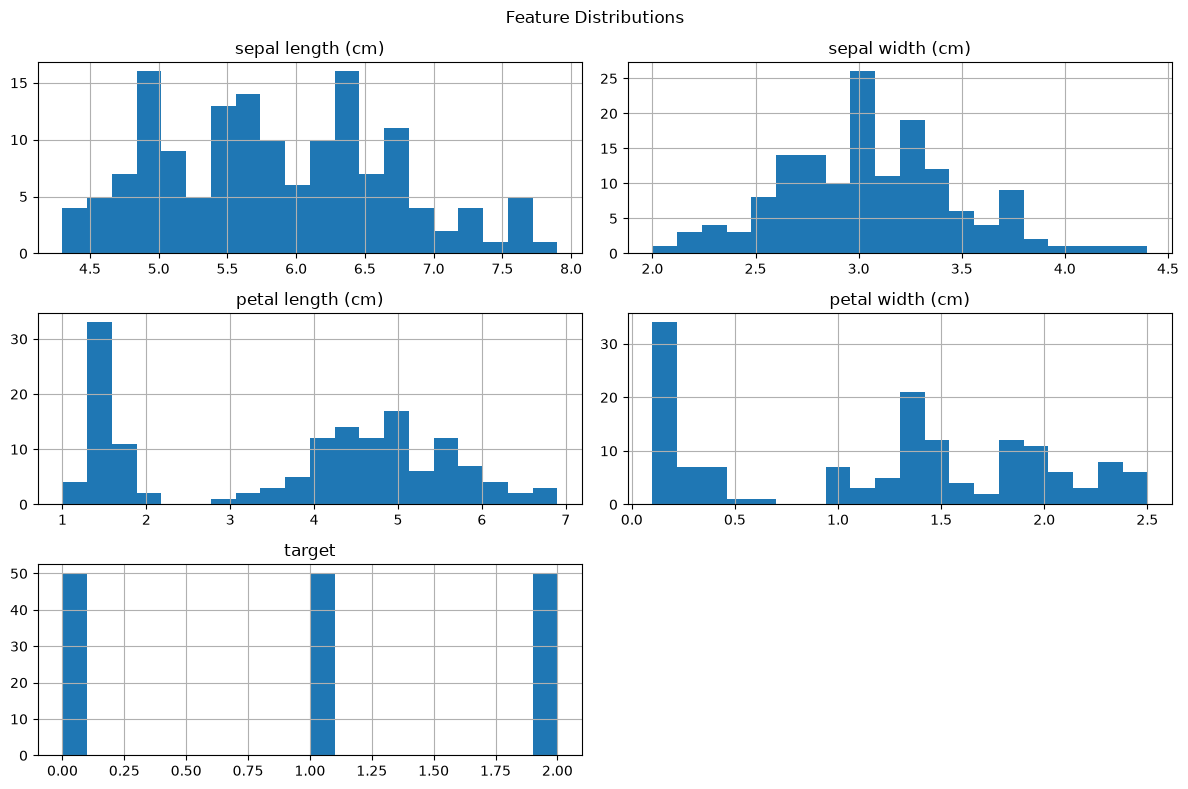

Outlier count:
sepal length (cm)    0
sepal width (cm)     4
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [7]:
# Feature distributions
df.hist(figsize=(12, 8), bins=20)
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

# Check outliers using IQR
numeric_df = df.drop(columns=["target"])

Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (numeric_df < (Q1 - 1.5 * IQR)) |
    (numeric_df > (Q3 + 1.5 * IQR))
).sum()

print("Outlier count:")
print(outliers)

## Distribution and Outlier Analysis

- Feature histograms were plotted to understand data distributions.
- The target variable contains three balanced classes.
- Sepal width contains 4 potential outliers using the IQR method.
- No potential outliers were detected in sepal length, petal length, and petal width.
- Outliers are identified for further investigation and are not removed.